In [1]:
# --- arranque en Colab (no hace nada fuera de Colab) -----------------------
# Colab arranca en /content con un entorno vacío: sin esta celda el
# `import environment` siguiente falla con ModuleNotFoundError. Generada por
# tools/py_to_notebook.py -- editala ahí, no acá.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/solidgoldmagickarp/proyecto_de_lenguaje_emergente.git"
    REPO_DIR = "proyecto_de_lenguaje_emergente"

    # El orden de las guardas importa: primero probar DÓNDE estamos, después qué hay en disco.
    # `isdir(REPO_DIR)` es relativo, así que chequearlo primero clonaría una copia
    # anidada en cualquier re-ejecución de esta celda dentro de la misma sesión (algo rutinario).
    if os.path.basename(os.getcwd()) != REPO_DIR:
        if not os.path.isdir(REPO_DIR):
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
        os.chdir(REPO_DIR)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True
    )

    # El disco de Colab es EFÍMERO: cada checkpoint se pierde cuando el entorno de ejecución
    # se desconecta (~90 min de inactividad en el plan gratuito), y las Etapas 3, 4 y 5 necesitan
    # todas los checkpoints de la Etapa 2. Descomentá para guardarlos en Drive en su lugar.
    #
    # Notar `islink`, no `exists`: importar `environment` crea un directorio checkpoints/
    # REAL, y `exists` entonces saltearía el enlace en silencio y mandaría cada
    # checkpoint de vuelta al disco efímero.
    #
    # from google.colab import drive
    # drive.mount("/content/drive")
    # PERSISTENT = "/content/drive/MyDrive/proyecto_de_lenguaje_emergente/checkpoints"
    # os.makedirs(PERSISTENT, exist_ok=True)
    # if os.path.islink("checkpoints"):
    #     print("checkpoints ->", os.readlink("checkpoints"))
    # elif os.path.isdir("checkpoints"):
    #     print("ADVERTENCIA: checkpoints/ ya es un directorio real, así que NO está en Drive.")
    #     print("Mové su contenido a", PERSISTENT, ", borralo, y volvé a ejecutar esta celda.")
    # else:
    #     os.symlink(PERSISTENT, "checkpoints")
    #     print("checkpoints ->", PERSISTENT)

    print("Arranque en Colab OK. Directorio de trabajo:", os.getcwd())

# Etapa 3 · La representación aprendida

La tabla de embeddings de tokens del modelo ancho entrenado, contra la del mismo modelo en el paso 0 (misma
semilla, sin entrenar). Usamos el ancho y no el profundo porque `pretrain_step0.pt` tiene su forma: comparar
contra un modelo sin entrenar de otro `n_embd` no tendría sentido.

Lee `checkpoints/tokenizer.json`, `pretrain_step0.pt`, `pretrain_wide.pt` y el cache de tokens de la Etapa 2.

In [2]:
import environment  # noqa: F401

environment.summary()

SMOKE_TEST = False  # solo cambia qué cache de tokens se usa para contar frecuencias
SEED = 1337
MIN_COUNT = 5 if SMOKE_TEST else 200  # un token que casi no apareció en entrenamiento sigue siendo ruido
N_RANDOM_PAIRS = 2_000

ENTORNO
os             : Windows 11
python         : 3.13.15
venv           : C:\dev\ia-generativa-sistemas-multiagente\tp\1\proyecto_de_lenguaje_emergente\.venv
cpu            : Intel64 Family 6 Model 158 Stepping 10, GenuineIntel
logical_cores  : 6
torch          : 2.11.0+cu128
torch_threads  : 6
cuda_available : True
gpu            : NVIDIA GeForce RTX 3050
gpu_memory_gb  : 6.44
ram_total_gb   : 17.1
ram_free_gb    : 5.3
--------------------------------------------------------------
HF_HOME        : C:\Users\juani\.cache\huggingface
ca_bundle      : no presente (normal)


In [3]:
import json

import numpy as np
from tokenizers import Tokenizer

from lab import load_checkpoint

tokenizer = Tokenizer.from_file("checkpoints/tokenizer.json")
trained, trained_ckpt = load_checkpoint("checkpoints/pretrain_wide.pt")
untrained, _ = load_checkpoint("checkpoints/pretrain_step0.pt")
assert trained.config == untrained.config, "paso 0 y entrenado tienen que tener la misma forma"

E_trained = trained.token_embedding_table.weight.detach().float().numpy()
E_untrained = untrained.token_embedding_table.weight.detach().float().numpy()
N_EMBD = E_trained.shape[1]
print(f"tabla de embeddings: {E_trained.shape} | entrenado {trained_ckpt.get('step')} pasos "
      f"(smoke_test={trained_ckpt.get('smoke_test')})")

# frecuencia de cada token en el corpus de preentrenamiento
tokens = np.load(f"checkpoints/tokens_{'smoke' if SMOKE_TEST else 'full'}.npz")["train"]
freq = np.bincount(tokens, minlength=tokenizer.get_vocab_size())
print(f"filas que nunca aparecieron en entrenamiento: {(freq == 0).sum():,} de {len(freq):,}")

tabla de embeddings: (8192, 256) | entrenado 6000 pasos (smoke_test=False)


filas que nunca aparecieron en entrenamiento: 212 de 8,192


## El pool de palabras enteras

Tokens `Ġ` + letras (el `Ġ` es el espacio adelante), con al menos `MIN_COUNT` apariciones. Todos los rankings
de vecinos se hacen adentro de este pool.

In [4]:
vocab = tokenizer.get_vocab()
whole_word = sorted((t, i) for t, i in vocab.items() if t.startswith("Ġ") and t[1:].isalpha() and freq[i] >= MIN_COUNT)
words = [t[1:] for t, _ in whole_word]
rows = np.array([i for _, i in whole_word])
word_index = {w: k for k, w in enumerate(words)}
print(f"palabras enteras con >= {MIN_COUNT} apariciones: {len(words):,}")


def unit_rows(E):
    return E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-12)


U_trained = unit_rows(E_trained[rows])
U_untrained = unit_rows(E_untrained[rows])


def cos(U, a, b):
    return float(U[word_index[a]] @ U[word_index[b]])


def nearest(U, word, topn=8):
    if word not in word_index:
        raise KeyError(f"{word!r} no es un token de palabra entera (frecuente) en este vocabulario")
    q = word_index[word]
    sims = U @ U[q]
    return [(words[i], round(float(sims[i]), 3)) for i in np.argsort(-sims) if i != q][:topn]

palabras enteras con >= 200 apariciones: 5,390


## El piso de ruido

Coseno entre vectores gaussianos al azar en `n_embd` dimensiones: media 0, desvío ≈ `1/√n_embd`. El máximo sobre
todo el pool es varias veces eso. Lo medimos de dos formas: simulando, y directamente sobre la tabla sin entrenar
(que *es* ruido al azar).

In [5]:
rng = np.random.default_rng(SEED)
sim = unit_rows(rng.standard_normal((len(words), N_EMBD)))
sim_cos = sim[1:] @ sim[0]
pair_i, pair_j = rng.integers(0, len(words), size=(2, N_RANDOM_PAIRS))
keep = pair_i != pair_j
pair_i, pair_j = pair_i[keep], pair_j[keep]
untrained_pairs = np.sum(U_untrained[pair_i] * U_untrained[pair_j], axis=1)
max_nn_untrained = np.mean([np.sort(U_untrained @ U_untrained[q])[-2] for q in rng.integers(0, len(words), 200)])

noise = {
    "1/sqrt(n_embd)": 1 / np.sqrt(N_EMBD),
    "desvío simulado": float(sim_cos.std()),
    "p99 |coseno| simulado": float(np.percentile(np.abs(sim_cos), 99)),
    "máximo simulado sobre el pool": float(sim_cos.max()),
    "desvío en tabla sin entrenar": float(untrained_pairs.std()),
    "vecino más cercano medio (sin entrenar)": float(max_nn_untrained),
}
for k, v in noise.items():
    print(f"{k:<42}: {v:.3f}")

1/sqrt(n_embd)                            : 0.062
desvío simulado                           : 0.063
p99 |coseno| simulado                     : 0.161
máximo simulado sobre el pool             : 0.212
desvío en tabla sin entrenar              : 0.062
vecino más cercano medio (sin entrenar)   : 0.229


## Pares elegidos, contra un grupo de control

Editen las listas: la consigna pide dos pares que esperan ver cerca y uno lejos, elegidos por ustedes. El control
son pares al azar del mismo pool. La pregunta no es "¿subió el coseno?" sino "¿subió *más* que en pares al azar?".

In [6]:
EXPECTED_CLOSE = [("dog", "cat"), ("happy", "sad"), ("mom", "dad"), ("red", "blue"), ("big", "small")]
EXPECTED_FAR = [("dog", "happy"), ("tree", "said"), ("blue", "ran")]

trained_pairs = np.sum(U_trained[pair_i] * U_trained[pair_j], axis=1)
control_delta = trained_pairs - untrained_pairs
print(f"control ({len(control_delta):,} pares al azar): coseno entrenado medio {trained_pairs.mean():+.3f} "
      f"(desvío {trained_pairs.std():.3f}); Δ medio {control_delta.mean():+.3f}\n")

print(f"{'par':<18} {'sin entrenar':>12} {'entrenado':>10} {'Δ':>7} {'percentil entrenado vs control':>31}")
pair_report = []
for label, pairs in (("cerca", EXPECTED_CLOSE), ("lejos", EXPECTED_FAR)):
    for a, b in pairs:
        if a not in word_index or b not in word_index:
            print(f"{a}/{b}: alguna no está en el pool, se saltea")
            continue
        c0, c1 = cos(U_untrained, a, b), cos(U_trained, a, b)
        pct = float((trained_pairs < c1).mean())
        pair_report.append({"grupo": label, "par": f"{a}/{b}", "untrained": c0, "trained": c1, "percentile": pct})
        print(f"{label}: {a + '/' + b:<11} {c0:>12.3f} {c1:>10.3f} {c1 - c0:>+7.3f} {pct:>31.1%}")

control (2,000 pares al azar): coseno entrenado medio +0.031 (desvío 0.096); Δ medio +0.030

par                sin entrenar  entrenado       Δ  percentil entrenado vs control
cerca: dog/cat           -0.063      0.572  +0.635                          100.0%
cerca: happy/sad          0.037      0.449  +0.412                           99.9%
cerca: mom/dad            0.010      0.583  +0.573                          100.0%
cerca: red/blue           0.065      0.731  +0.665                          100.0%
cerca: big/small          0.056      0.521  +0.465                          100.0%
lejos: dog/happy         -0.069      0.052  +0.122                           62.3%
lejos: tree/said         -0.010      0.050  +0.060                           61.2%
lejos: blue/ran          -0.012     -0.080  -0.068                           11.2%


## Vecinos más cercanos, antes y después

In [7]:
QUERIES = ["dog", "happy", "mom", "red", "ball", "run", "tree", "king", "one", "night"]
for w in QUERIES:
    if w not in word_index:
        continue
    print(f"{w:>6} | entrenado  : {nearest(U_trained, w)}")
    print(f"{'':>6} | sin entrenar: {nearest(U_untrained, w, topn=5)}\n")

   dog | entrenado  : [('cat', 0.572), ('puppy', 0.566), ('Rex', 0.47), ('Spot', 0.441), ('kitten', 0.439), ('doggy', 0.438), ('bear', 0.429), ('boy', 0.411)]
       | sin entrenar: [('score', 0.262), ('waved', 0.198), ('giraffes', 0.197), ('apple', 0.191), ('guest', 0.188)]

 happy | entrenado  : [('glad', 0.556), ('pleased', 0.494), ('delighted', 0.483), ('relieved', 0.481), ('lucky', 0.478), ('cheerful', 0.472), ('excited', 0.472), ('sad', 0.449)]
       | sin entrenar: [('pedals', 0.237), ('ostrich', 0.206), ('re', 0.194), ('John', 0.192), ('hugging', 0.18)]

   mom | entrenado  : [('mommy', 0.702), ('Mom', 0.688), ('mum', 0.676), ('mother', 0.671), ('dad', 0.583), ('Mommy', 0.58), ('grandma', 0.571), ('parents', 0.535)]
       | sin entrenar: [('temperature', 0.212), ('porch', 0.204), ('country', 0.198), ('conversation', 0.197), ('keeps', 0.191)]

   red | entrenado  : [('blue', 0.731), ('yellow', 0.688), ('pink', 0.673), ('purple', 0.598), ('green', 0.577), ('silver', 0.519), ('w

## Estructura por grupos semánticos

Un número en lugar de una impresión: coseno medio *dentro* de cada grupo menos coseno medio *entre* grupos.
En la tabla sin entrenar debería dar ≈ 0.

In [8]:
GROUPS = {
    "animales": ["dog", "cat", "bird", "fish", "bear", "rabbit", "duck", "frog", "lion", "cow", "horse", "mouse"],
    "colores": ["red", "blue", "green", "yellow", "pink", "purple", "orange", "white", "black", "brown"],
    "familia": ["mom", "dad", "mommy", "daddy", "sister", "brother", "grandma", "grandpa", "friend"],
    "emociones": ["happy", "sad", "angry", "scared", "excited", "proud", "sorry", "surprised", "worried"],
    "verbos_pasado": ["ran", "jumped", "played", "walked", "looked", "said", "saw", "went", "found", "smiled"],
    "comida": ["cake", "apple", "cookie", "milk", "bread", "candy", "soup", "pizza", "banana", "juice"],
}
GROUPS = {g: [w for w in ws if w in word_index] for g, ws in GROUPS.items()}
GROUPS = {g: ws for g, ws in GROUPS.items() if len(ws) >= 3}


def group_separation(U):
    idx = {g: [word_index[w] for w in ws] for g, ws in GROUPS.items()}
    within, between = [], []
    names = list(idx)
    for a_pos, g in enumerate(names):
        S = U[idx[g]] @ U[idx[g]].T
        within.append(S[np.triu_indices(len(idx[g]), 1)].mean())
        for h in names[a_pos + 1:]:
            between.append((U[idx[g]] @ U[idx[h]].T).mean())
    return float(np.mean(within)), float(np.mean(between))


for label, U in (("sin entrenar", U_untrained), ("entrenado", U_trained)):
    w_in, w_out = group_separation(U)
    print(f"{label:<13}: dentro {w_in:+.3f} | entre {w_out:+.3f} | separación {w_in - w_out:+.3f}")

sin entrenar : dentro +0.000 | entre +0.000 | separación +0.000
entrenado    : dentro +0.351 | entre +0.045 | separación +0.307


## Proyección 2D, lado a lado

Las palabras de los grupos de arriba, más las palabras enteras más frecuentes como fondo gris. PCA es lineal y
conserva distancias globales; t-SNE conserva vecindarios locales pero exagera los clusters, así que mostramos los
dos.

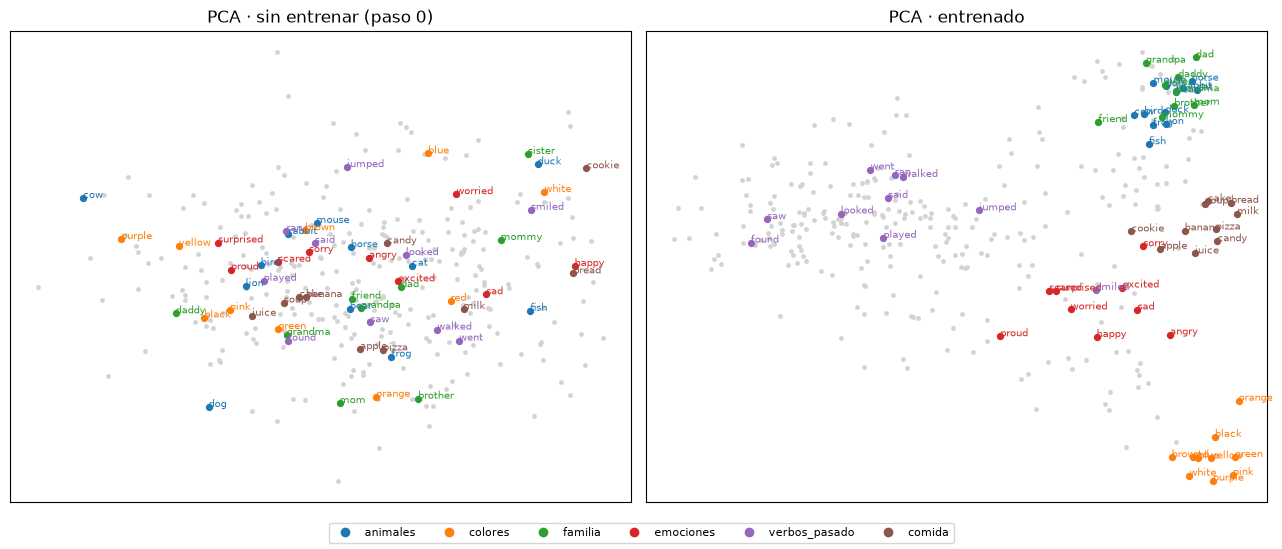

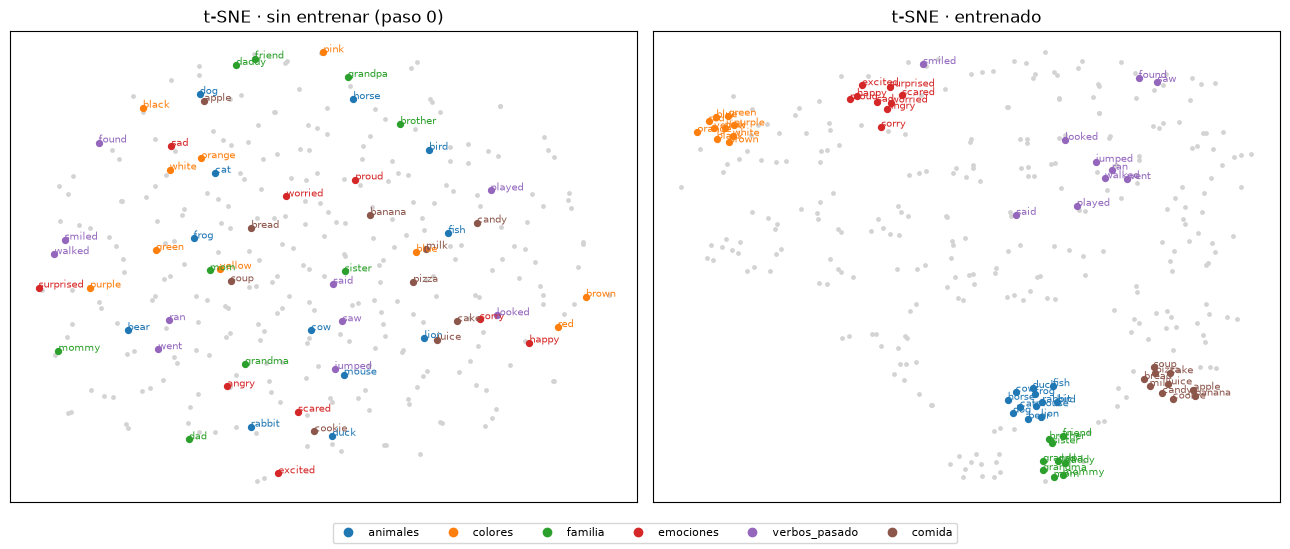

In [9]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

group_words = [(w, g) for g, ws in GROUPS.items() for w in ws]
background = [words[k] for k in np.argsort(-freq[rows])[:300] if words[k] not in dict(group_words)]
plot_words = [w for w, _ in group_words] + background
plot_idx = [word_index[w] for w in plot_words]
colors = dict(zip(GROUPS, plt.cm.tab10.colors))

for method in ("PCA", "t-SNE"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, (label, U) in zip(axes, (("sin entrenar (paso 0)", U_untrained), ("entrenado", U_trained))):
        X = U[plot_idx]
        if method == "PCA":
            P = PCA(n_components=2, random_state=SEED).fit_transform(X)
        else:
            P = TSNE(n_components=2, perplexity=min(30, len(X) - 1), metric="cosine", init="pca",
                     random_state=SEED).fit_transform(X)
        n_g = len(group_words)
        ax.scatter(P[n_g:, 0], P[n_g:, 1], s=6, c="lightgray")
        for (w, g), (x, y) in zip(group_words, P[:n_g]):
            ax.scatter(x, y, s=18, color=colors[g])
            ax.annotate(w, (x, y), fontsize=7, color=colors[g])
        ax.set_title(f"{method} · {label}")
        ax.set_xticks([])
        ax.set_yticks([])
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in colors.items()]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=8)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(f"checkpoints/stage3_{method.lower().replace('-', '')}.png", dpi=110)
    plt.show()

## ¿Qué pasa si no filtramos a palabras enteras?

Mismas consultas, rankeando sobre *todo* el vocabulario. Y la trampa del token duplicado: `Ġday` contra el pedazo
`day` (el de `birthday`), con cuántas veces apareció cada uno en entrenamiento.

In [10]:
id_to_tok = {i: t for t, i in vocab.items()}
U_all = unit_rows(E_trained)
for w in QUERIES[:5]:
    tid = vocab.get("Ġ" + w)
    if tid is None:
        continue
    sims = U_all @ U_all[tid]
    top = [id_to_tok[i] for i in np.argsort(-sims)[1:11]]
    frac_ww = np.mean([t.startswith("Ġ") and t[1:].isalpha() for t in top])
    print(f"Ġ{w:<6} -> {top} ({frac_ww:.0%} palabras enteras)")

print()
for w in ("day", "ball", "play", "happy"):
    if "Ġ" + w in vocab and w in vocab:
        a, b = vocab["Ġ" + w], vocab[w]
        print(f"'Ġ{w}' (id {a}, {freq[a]:,} apariciones) vs '{w}' (id {b}, {freq[b]:,} apariciones): "
              f"coseno entre ambas filas {float(U_all[a] @ U_all[b]):+.3f}")
        sims = U_all @ U_all[b]
        print(f"   vecinos del pedazo '{w}': {[id_to_tok[i] for i in np.argsort(-sims)[1:8]]}")

Ġdog    -> ['Ġcat', 'Ġpuppy', 'ĠRex', 'ĠSpot', 'Ġkitten', 'Ġdoggy', 'Ġbear', 'Ġboy', 'Ġpup', 'Ġneighbor'] (100% palabras enteras)
Ġhappy  -> ['Ġglad', 'Ġpleased', 'Ġdelighted', 'Ġrelieved', 'Ġlucky', 'Ġcheerful', 'Ġexcited', 'Ġsad', 'Ġoverjoyed', 'Ġproud'] (100% palabras enteras)
Ġmom    -> ['Ġmommy', 'ĠMom', 'Ġmum', 'Ġmother', 'Ġdad', 'ĠMommy', 'Ġgrandma', 'Mom', 'Ġparents', 'ĠMum'] (90% palabras enteras)
Ġred    -> ['Ġblue', 'Ġyellow', 'Ġpink', 'Ġpurple', 'Ġgreen', 'Ġsilver', 'Ġwhite', 'Ġorange', 'Ġbrown', 'Ġblack'] (100% palabras enteras)
Ġball   -> ['Ġcar', 'Ġhoop', 'Ġkite', 'Ġbutterfly', 'Ġfootball', 'Ġblock', 'Ġtruck', 'Ġwagon', 'Ġballs', 'Ġglove'] (100% palabras enteras)

'Ġday' (id 356, 629,001 apariciones) vs 'day' (id 1114, 253 apariciones): coseno entre ambas filas +0.288
   vecinos del pedazo 'day': ['Finally', 'ĠInside', 'ĠFinally', 'urious', 'Suddenly', 'ĠEveryday', 'ĠEventually']
'Ġball' (id 670, 82,612 apariciones) vs 'ball' (id 2150, 827 apariciones): coseno entre amba

In [11]:
with open("checkpoints/stage3_embeddings.json", "w", encoding="utf-8") as f:
    json.dump({"noise_floor": noise, "pairs": pair_report,
               "control_trained_mean": float(trained_pairs.mean()), "control_trained_std": float(trained_pairs.std()),
               "group_separation": {"untrained": group_separation(U_untrained), "trained": group_separation(U_trained)}},
              f, ensure_ascii=False, indent=1)

## Para el informe

- Dos pares que esperaban cerca y uno lejos: ¿le pegaron, y la diferencia le gana al piso de ruido y al control?
- ¿Qué cambió a la vista entre la proyección sin entrenar y la entrenada? ¿Coincide con el número de separación
  por grupos, o el gráfico sugiere más (o menos) de lo que el número respalda?
- ¿Filtrar a palabras enteras cambia lo que ven, comparado con incluir pedazos sub-palabra?
- Si el espacio entrenado se parece bastante al no entrenado, ¿qué cambiarían para moverlo, y qué costaría?